In [1]:
from rdkit.Chem.Draw import IPythonConsole
from rdkit.Chem import rdDepictor
from rdkit import Chem

IPythonConsole.ipython_useSVG = True
IPythonConsole.molSize = 300, 300
rdDepictor.SetPreferCoordGen(True)

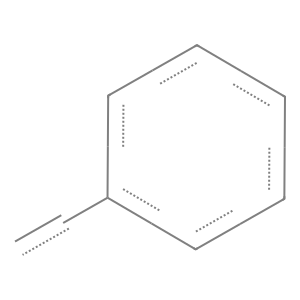

In [2]:
query_mol = Chem.MolFromSmarts("c1ccccc1C")
query_mol

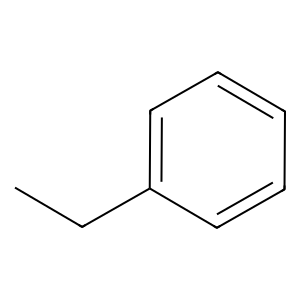

In [3]:
ethyl_benzene = Chem.MolFromSmiles("c1ccccc1CC")
ethyl_benzene

In [4]:
ethyl_benzene.HasSubstructMatch(query_mol)

True

In [5]:
ethyl_benzene.GetSubstructMatch(query_mol)

(0, 1, 2, 3, 4, 5, 6)

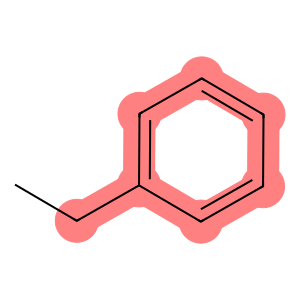

In [6]:
ethyl_benzene

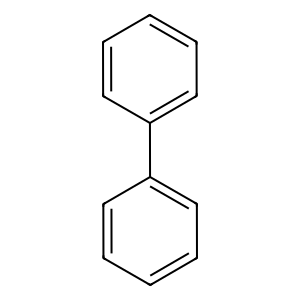

In [7]:
biphenyl = Chem.MolFromSmiles("c1ccccc1c2ccccc2")
biphenyl

In [8]:
biphenyl.HasSubstructMatch(query_mol)

False

In [9]:
new_query_mol = Chem.MolFromSmarts("c1ccccc1[#6]")
biphenyl.HasSubstructMatch(new_query_mol)

True

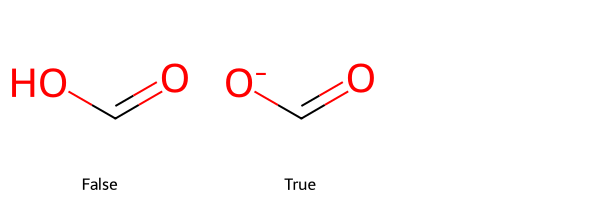

In [10]:
# An list of SMILES with acetic acid and acetate anion
smiles_list = ["C(=O)O","C(=O)[O-]"]
# Convert SMILES to RDKit molecules
mol_list = [Chem.MolFromSmiles(x) for x in smiles_list]
# Create a query molecule from SMARTS
anion_query = Chem.MolFromSmarts("[-1]")
# Match the query to the molecules, convert the output to string so that MolsToGrid can display as a legend
match_list = [str(x.HasSubstructMatch(anion_query)) for x in mol_list]
# Draw the structures
Chem.Draw.MolsToGridImage(mol_list,legends=match_list)

In [11]:
smiles_list = ["c1ccccc1","c1ccccn1"]
mol_list = [Chem.MolFromSmiles(x) for x in smiles_list]
query_mol = Chem.MolFromSmarts("c1cccc[c,n]1")
[x.HasSubstructMatch(query_mol) for x in mol_list]

[True, True]

In [12]:
smiles_list = ["c1ccccc1C","c1ccccc1c2ccccc2" ]
mol_list = [Chem.MolFromSmiles(x) for x in smiles_list]
query_mol = Chem.MolFromSmarts("c1cccc[c,C]1")
[x.HasSubstructMatch(query_mol) for x in mol_list]

[True, True]

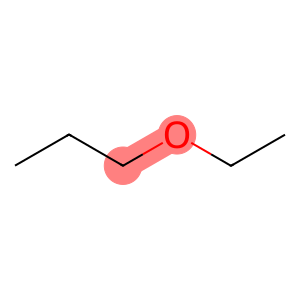

In [13]:
mol = Chem.MolFromSmiles("CCCOCC")
query_mol = Chem.MolFromSmarts("C[#7,#8]")
mol.GetSubstructMatch(query_mol)
mol

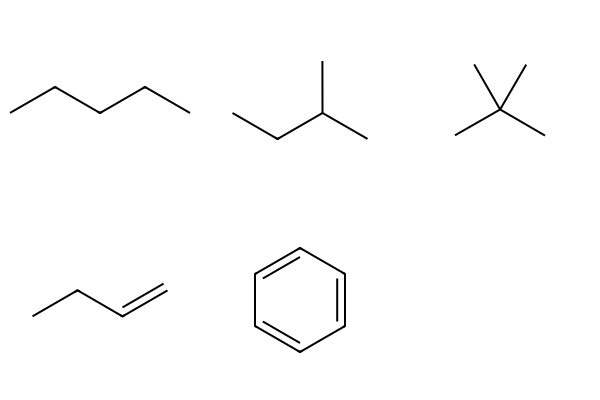

In [14]:
smiles_list = ["CCCCC","CC(C)CC","CC(C)(C)C","C=CCC","c1ccccc1"]
mol_list = [Chem.MolFromSmiles(x) for x in smiles_list]
Chem.Draw.MolsToGridImage(mol_list)

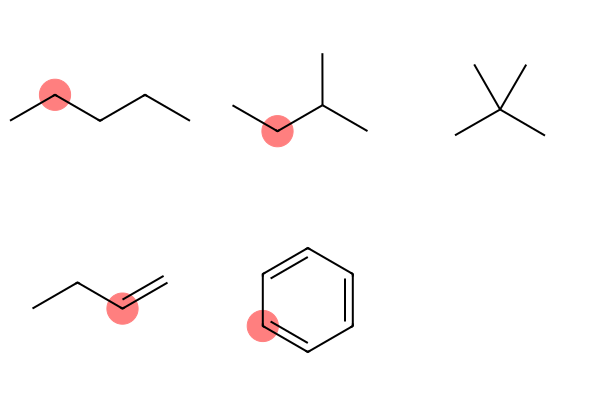

In [15]:
query_smarts = "[D2]"
query_mol = Chem.MolFromSmarts(query_smarts)
match_list = []
for mol in mol_list:
    match_list.append(mol.GetSubstructMatch(query_mol))
Chem.Draw.MolsToGridImage(mol_list,highlightAtomLists=match_list)

In [16]:
mol_list[0].GetSubstructMatches(query_mol)

((1,), (2,), (3,))

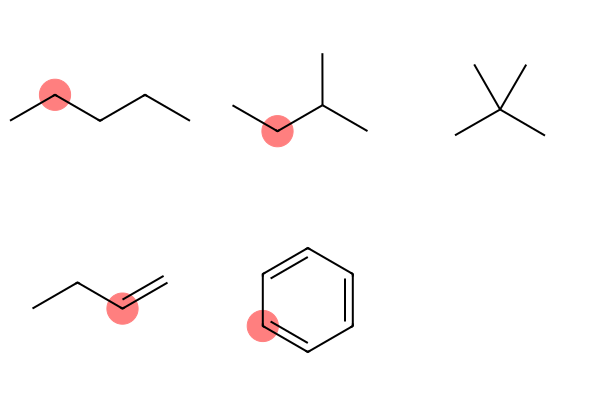

In [17]:
Chem.Draw.MolsToGridImage(mol_list,highlightAtomLists=match_list)

In [18]:
import mols2grid
mols2grid.display(mol_list,substruct_highlight=True)

In [28]:
import pandas as pd
import mols2grid

df = pd.read_csv(
    "https://raw.githubusercontent.com/PatWalters/practical_cheminformatics_tutorials/main/data/smarts_test.smi",
    sep=" ",
    names=["SMILES", "Name"]
)



In [29]:
mols2grid.display(
    df,
    smiles_col="SMILES",
    subset=["img", "Name"]
)

In [33]:
import pandas as pd
import mols2grid

url = "https://raw.githubusercontent.com/PatWalters/practical_cheminformatics_tutorials/main/data/smarts_test.smi"

df = pd.read_csv(
    url,
    sep=r"\s+",
    header=None,
    names=["Group", "SMILES", "Name"]
)

df.head()

,Group,SMILES,Name
0,7,CN1C(=O)CO[C@H]2CNC[C@@H]21,95346843
1,78,N[S@](=O)C1CS(=O)(=O)C1,675072173
2,5,CNC(=O)c1n[nH]c(N)n1,19844301
3,64,NC1=NC[C@@H](C(=O)O)CN1,38415755
4,62,N=C(N)NC[C@@H](N)C(=O)O,1576365


In [36]:
import pandas as pd
df = pd.read_csv("https://raw.githubusercontent.com/PatWalters/practical_cheminformatics_tutorials/main/data/smarts_test.smi",sep=" ",names=["SMILES","Name"])
mols2grid.display(df,subset=["img","Name"])

In [37]:
from IPython.display import display


mols2grid.display(
        df,
        smiles_col="SMILES",
        subset=["img", "Name"],
        prerender=True
    )